# Loading and discovering the data: 

In [ ]:
import pandas as pd

df = pd.read_csv("../data/pjme-hourly.csv")

In [5]:
df.shape

(145366, 2)

In [6]:
df.describe()

,PJME_MW
count,145366.000000
mean,32080.222831
std,6464.012166
min,14544.000000
25%,27573.000000
50%,31421.000000
75%,35650.000000
max,62009.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  str    
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), str(1)
memory usage: 4.9 MB


In [8]:
df.isna().sum()

Datetime    0
PJME_MW     0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

Datetime        str
PJME_MW     float64
dtype: object

datetime comes as str which is a problem so we should convert them to real dates

In [11]:
df["Datetime"] = pd.to_datetime(df["Datetime"], format="%Y-%m-%d %H:%M:%S")
df.dtypes

Datetime    datetime64[us]
PJME_MW            float64
dtype: object

In [12]:
print(df["Datetime"].is_monotonic_increasing)

False


datetimes are not sorted

In [13]:
df["Datetime"].dt.year.value_counts().sort_index()

Datetime
2002    8757
2003    8758
2004    8782
2005    8758
2006    8758
2007    8758
2008    8782
2009    8758
2010    8757
2011    8758
2012    8782
2013    8758
2014    8760
2015    8760
2016    8784
2017    8760
2018    5136
Name: count, dtype: int64

In [16]:
expected = pd.date_range(df["Datetime"].min(), df["Datetime"].max(), freq="h")
missing = expected.difference(df["Datetime"])

print("missing hours: ", len(missing))
pd.Series(missing.year).value_counts().sort_index()

missing hours:  30


2002    2
2003    2
2004    2
2005    2
2006    2
2007    2
2008    2
2009    2
2010    3
2011    2
2012    2
2013    2
2014    1
2015    1
2016    1
2017    1
2018    1
Name: count, dtype: int64

#### 30 hours are missing:

##### 2014-2018: misseing 1 hour
##### 2002-2009 and 2011-13 : missing 2 hours
##### 2010: misses 3 hours   

# Clean phase:

In [19]:
df = df.sort_values("Datetime")
print(df["Datetime"].is_monotonic_increasing)

True


In [21]:
df["Datetime"].duplicated().sum()

np.int64(4)

In [22]:
df[df["Datetime"].duplicated()]

,Datetime,PJME_MW
106584,2014-11-02 02:00:00,22935.0
115369,2015-11-01 02:00:00,21171.0
124009,2016-11-06 02:00:00,21692.0
132817,2017-11-05 02:00:00,20666.0


In [23]:
df = df.groupby("Datetime", as_index=False)["PJME_MW"].mean()

In [24]:
df["Datetime"].duplicated().sum()

np.int64(0)

4 duplicated dates appear twice so I combine them by their mean to become one single value

In [25]:
df = df.set_index("Datetime")
df = df.asfreq("h")

Rebuild the full hourly calendar. The 30 missing rows becomes existed with PJME_MW as a missing value

In [26]:
df.isna().sum()

PJME_MW    30
dtype: int64

In [27]:
df[df["PJME_MW"].isna()].head(10)

,PJME_MW
Datetime,
2002-04-07 03:00:00,NaN
2002-10-27 02:00:00,NaN
2003-04-06 03:00:00,NaN
2003-10-26 02:00:00,NaN
2004-04-04 03:00:00,NaN
2004-10-31 02:00:00,NaN
2005-04-03 03:00:00,NaN
2005-10-30 02:00:00,NaN
2006-04-02 03:00:00,NaN


In [28]:
df["PJME_MW"] = df["PJME_MW"].interpolate(method="time")

In [29]:
print(df["PJME_MW"].isna().sum())  

0


filled the missing 30 hours with interpolate which create a point between the two points around each missing and it gets the value from that

In [ ]:
df.nsmallest(15, "PJME_MW")

,PJME_MW
Datetime,
2012-10-30 04:00:00,14544.0
2012-10-30 03:00:00,14586.0
2012-10-30 05:00:00,14821.0
2012-10-30 02:00:00,14955.0
2012-10-30 01:00:00,15390.0
2012-10-30 06:00:00,15526.0
2012-10-30 00:00:00,15919.0
2012-10-30 07:00:00,16688.0
2012-10-29 23:00:00,17422.0


<Axes: xlabel='Datetime'>

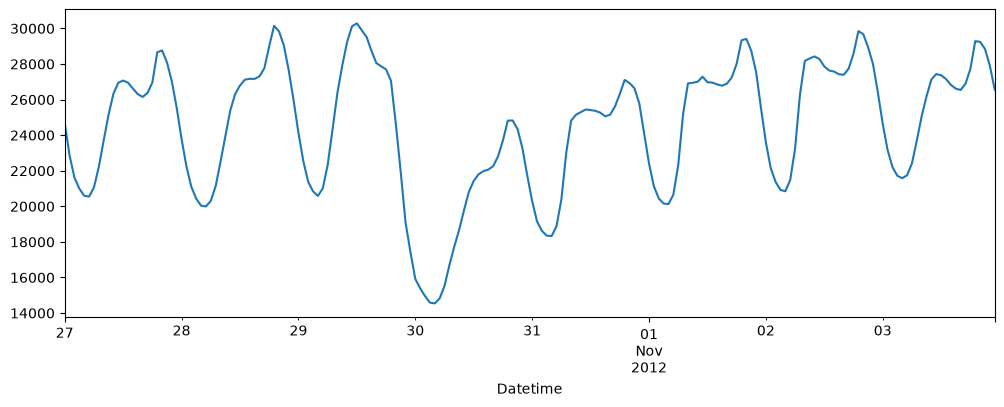

In [37]:
date = df.loc["2012-10-27":"2012-11-03", "PJME_MW"]
date.plot(figsize=(12, 4))

we notice a PJME slide down in late october which was because of Hurricane Sandy which hit US that time and make millions of homes lost power

In [40]:
jumps = df["PJME_MW"].diff()
jumps.abs().nlargest(10)

Datetime
2012-06-30 00:00:00    6866.0
2002-11-19 05:00:00    6326.0
2002-03-28 18:00:00    5629.0
2003-07-20 11:00:00    5115.0
2008-06-10 00:00:00    4925.0
2011-06-02 00:00:00    4888.0
2007-06-27 23:00:00    4810.0
2005-06-09 00:00:00    4681.0
2006-07-18 00:00:00    4670.0
2012-06-29 23:00:00    4663.0
Name: PJME_MW, dtype: float64

### Causes:
##### 2012-06-29 / 2012-06-30 : the June 2012 derecho 
##### 2005-06-09, 2006-07-18, 2007-06-27, 2008-06-10, 2011-06-02: air-conditioning usage in hot days 
##### All values seems logical and nothing impossible so we keep them all 
